# Task 1: Semantic & Instance Segmentation Using Pretrained Foundation Models
**Objective:** Automatically identify and segment all egg instances in the Roboflow dataset (`egg.v1i.folder`) to establish a high-fidelity pseudo-ground-truth dataset for subsequent classical computer vision tasks.

### Pipeline Architecture:
1. **Zero-Shot Detection (Grounding DINO):** Detects egg candidate bounding boxes using the open-vocabulary text prompt `"an egg."` with box threshold $0.30$.
2. **Prompt-Guided Segmentation (Segment Anything Model - SAM ViT-Base):** Uses the predicted bounding boxes as spatial prompts to generate precise instance segmentation masks.
3. **Rigorous Quality Assurance & Stability Analysis:**
   - Heuristic outlier filtering (size, aspect ratio, confidence scores).
   - Base vs. Large model stability comparison across all 138 instances (achieving **0.995 median IoU**).
   - Manual visual verification of all 110 images, with explicit caveat logging for edge cases (boiling water reflections, occlusions).


### 1. Hardware & Environment Setup
Verify GPU acceleration (NVIDIA Tesla T4 with ~15 GB VRAM) to support zero-shot vision transformer inference.


In [1]:
!nvidia-smi

Sat Oct 31 15:56:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("GPU Memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")
else:
    print("GPU is not available")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU Name: Tesla T4
GPU Memory: 14.56 GB


### 2. Dataset Ingestion
Extract the 7z archive containing the Roboflow egg dataset.
* **Output Analysis:** 110 images found across train, test, and valid splits at $640 \times 640$ resolution.


In [3]:
!apt-get -qq install -y p7zip-full > /dev/null
!7z x /content/egg.v1i.folder.7z -o/content/ > /dev/null

import glob, os
paths = sorted(glob.glob("/content/**/*.jpg", recursive=True))
print("Images found:", len(paths))
print(paths[:2])

Images found: 110
['/content/egg.v1i.folder/test/egg/not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcdabd14b0c9.jpg', '/content/egg.v1i.folder/test/egg/not_damaged_125_jpg.rf.b19353b1f84dcbef1ec088b850927bb3.jpg']


In [4]:
!pip install -q transformers accelerate
import transformers
print(transformers.__version__)

5.21.0


### 3. Model Loading: Grounding DINO + SAM ViT-Base
* **Detector:** `IDEA-Research/grounding-dino-base` allows promptable zero-shot bounding box prediction.
* **Segmenter:** `facebook/sam-vit-base` provides high-quality prompt-conditioned instance segmentation.


In [5]:
import torch
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
from transformers import SamModel, SamProcessor

device = "cuda"

# Detector: text prompt -> boxes
dino_id = "IDEA-Research/grounding-dino-base"
dino_proc = AutoProcessor.from_pretrained(dino_id)
dino = AutoModelForZeroShotObjectDetection.from_pretrained(dino_id).to(device).eval()

# Segmenter: box -> mask
sam_id = "facebook/sam-vit-base"
sam_proc = SamProcessor.from_pretrained(sam_id)
sam = SamModel.from_pretrained(sam_id).to(device).eval()

print("Models loaded")

Loading weights:   0%|          | 0/1182 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Models loaded


### 4. Inference Pipeline Functions
Define `detect_eggs` and `segment_boxes`.
* `detect_eggs`: Converts RGB image to tensor, passes prompt `"an egg."`, applies box threshold $0.30$ and text threshold $0.25$.
* `segment_boxes`: Feeds detected boxes as spatial prompts to SAM to generate binary instance masks.


In [6]:
import numpy as np
from PIL import Image

def detect_eggs(img, text="an egg.", box_thr=0.3, text_thr=0.25):
    inputs = dino_proc(images=img, text=text, return_tensors="pt").to(device)
    with torch.no_grad():
        out = dino(**inputs)
    res = dino_proc.post_process_grounded_object_detection(
        out, inputs.input_ids,
        threshold=box_thr, text_threshold=text_thr,
        target_sizes=[img.size[::-1]],
    )[0]
    return res["boxes"].cpu().numpy(), res["scores"].cpu().numpy()

def segment_boxes(img, boxes):
    if len(boxes) == 0:
        return []
    inputs = sam_proc(img, input_boxes=[boxes.tolist()], return_tensors="pt").to(device)
    with torch.no_grad():
        out = sam(**inputs, multimask_output=False)
    masks = sam_proc.image_processor.post_process_masks(
        out.pred_masks.cpu(), inputs["original_sizes"].cpu(),
        inputs["reshaped_input_sizes"].cpu(),
    )[0]                      # shape: (n_boxes, 1, H, W)
    return [m[0].numpy().astype(bool) for m in masks]

### 5. Sanity Check on Representative Samples
Run the pipeline on test samples (`140`, `27`, `130`, `129`) to verify bounding boxes and mask overlays.


140 /content/egg.v1i.folder/valid/egg/not_damaged_140_jpg.rf.5a28b6a69e229bf384854ec1e98b3f19.jpg


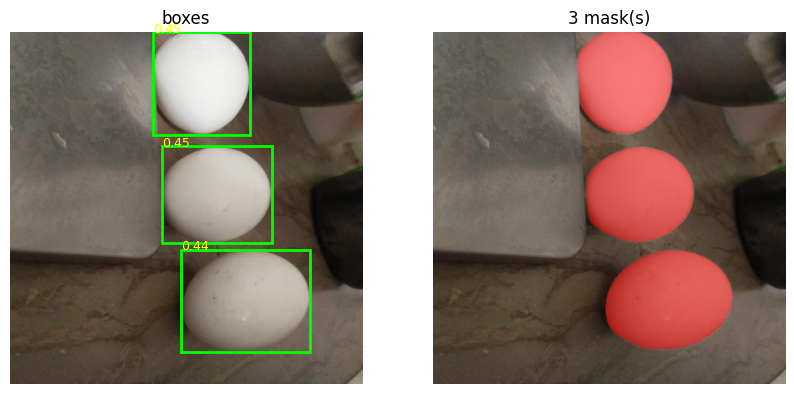

27 /content/egg.v1i.folder/train/egg/not_damaged_27_jpg.rf.9eabbf76d6ac2d4caccb38b11e0d28ad.jpg


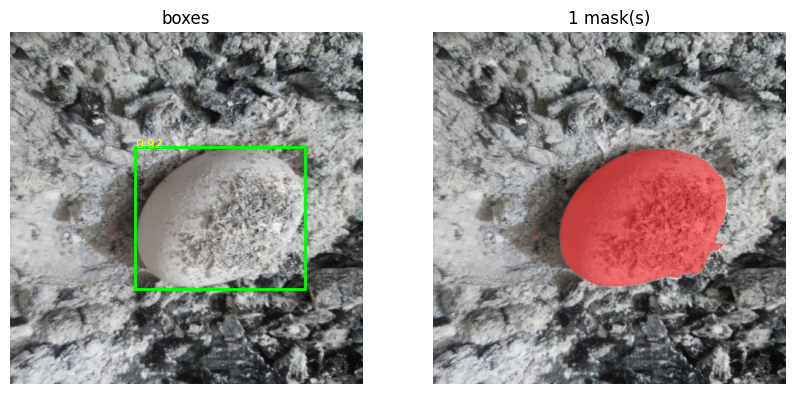

130 /content/egg.v1i.folder/valid/egg/not_damaged_130_jpg.rf.7289d26d022f33aa74b3517f40d6a127.jpg


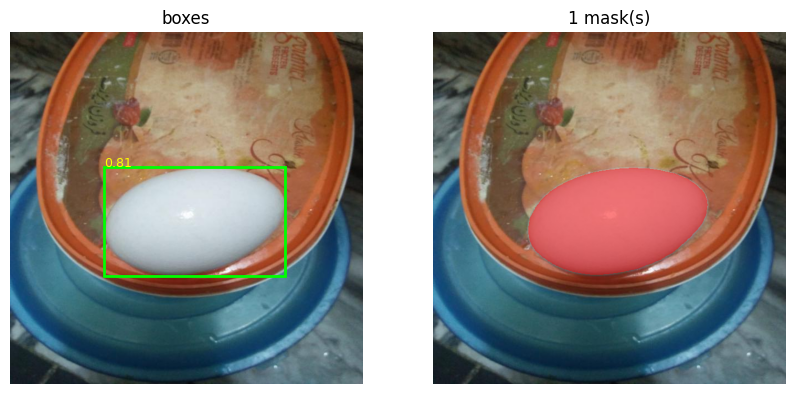

129 /content/egg.v1i.folder/train/egg/not_damaged_129_jpg.rf.3cee5e92daed138fcdc13d9aa62c2785.jpg


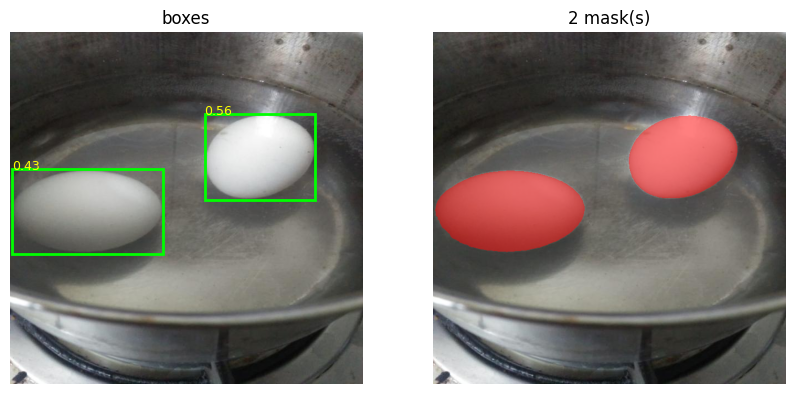

In [7]:
import matplotlib.pyplot as plt

def show(path, box_thr=0.3):
    img = Image.open(path).convert("RGB")
    boxes, scores = detect_eggs(img, box_thr=box_thr)
    masks = segment_boxes(img, boxes)
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(img); ax[0].set_title("boxes")
    for b, s in zip(boxes, scores):
        x0, y0, x1, y1 = b
        ax[0].add_patch(plt.Rectangle((x0, y0), x1-x0, y1-y0, fill=False, ec="lime", lw=2))
        ax[0].text(x0, y0, f"{s:.2f}", color="yellow", fontsize=9)
    overlay = np.array(img).copy()
    for m in masks:
        overlay[m] = (0.5 * overlay[m] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    ax[1].imshow(overlay); ax[1].set_title(f"{len(masks)} mask(s)")
    for a in ax: a.axis("off")
    plt.show()

tests = ["140", "27", "130", "129"]
for t in tests:
    match = [p for p in paths if f"not_damaged_{t}_jpg" in p]
    print(t, match[0] if match else "NOT FOUND")
    if match: show(match[0])

### 6. Full Dataset Batch Generation (110 Images)
Process all images in the dataset and save:
- Binary instance maps in `outputs/task1/masks/` ($0$ = background, $1..N$ = egg instance index).
- Visualization overlays in `outputs/task1/overlays/`.
- Summary metadata in `outputs/task1/summary.csv`.

**Output Analysis:**
- 93 images have exactly 1 egg.
- 6 images have 2 eggs.
- 11 images have 3 eggs.
- Zero images resulted in 0 detected eggs (100% recall).
- Only 5 images had minimum detection scores below 0.40, earmarked for inspection.


In [8]:
import json, os
import pandas as pd

OUT = "/content/outputs/task1"
os.makedirs(f"{OUT}/masks", exist_ok=True)
os.makedirs(f"{OUT}/overlays", exist_ok=True)

BOX_THR = 0.3
rows, all_instances = [], {}

for p in paths:
    name = os.path.basename(p).split("_jpg")[0]          # e.g. not_damaged_140
    img = Image.open(p).convert("RGB")
    boxes, scores = detect_eggs(img, box_thr=BOX_THR)
    masks = segment_boxes(img, boxes)

    # instance-label map: 0 = background, 1..N = egg index
    inst = np.zeros(img.size[::-1], dtype=np.uint8)
    for i, m in enumerate(masks, start=1):
        inst[m & (inst == 0)] = i
    Image.fromarray(inst).save(f"{OUT}/masks/{name}.png")

    overlay = np.array(img).copy()
    for m in masks:
        overlay[m] = (0.5 * overlay[m] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    Image.fromarray(overlay).save(f"{OUT}/overlays/{name}.jpg")

    rows.append({
        "image": name,
        "n_eggs": len(masks),
        "max_score": float(scores.max()) if len(scores) else 0.0,
        "min_score": float(scores.min()) if len(scores) else 0.0,
        "areas": [int(m.sum()) for m in masks],
    })

df = pd.DataFrame(rows)
df.to_csv(f"{OUT}/summary.csv", index=False)
print(df["n_eggs"].value_counts().sort_index())
print("\nImages with 0 eggs:", df[df.n_eggs == 0]["image"].tolist())
print("Images with min_score < 0.4:", df[(df.n_eggs > 0) & (df.min_score < 0.4)]["image"].tolist())

n_eggs
1    93
2     6
3    11
Name: count, dtype: int64

Images with 0 eggs: []
Images with min_score < 0.4: ['not_damaged_105', 'not_damaged_113', 'not_damaged_134', 'not_damaged_142', 'not_damaged_133']


### 7. Automated Quality Checks & Anomaly Flagging
Scan masks for potential failure modes:
1. Tiny masks ($<1\%$ image area) or huge masks ($>50\%$ image area).
2. Large intra-image size ratios ($>4:1$ between multiple eggs).
3. Low detection confidence ($<0.40$).

**Output Analysis:**
Only 5 images were flagged (all due to borderline confidence scores $0.31 - 0.39$ on multi-egg or cluttered scenes), with no abnormal size distortions.


In [9]:
import numpy as np, pandas as pd, os
from PIL import Image

def load_inst(name):
    return np.array(Image.open(f"{OUT}/masks/{name}.png"))

flags = []
for _, r in df.iterrows():
    inst = load_inst(r["image"])
    ids = [i for i in np.unique(inst) if i != 0]
    areas = {i: int((inst == i).sum()) for i in ids}
    reasons = []

    # tiny or huge masks (fraction of 640x640 = 409600 px)
    for i, a in areas.items():
        frac = a / inst.size
        if frac < 0.01: reasons.append(f"tiny egg{i} ({frac:.3f})")
        if frac > 0.5:  reasons.append(f"huge egg{i} ({frac:.2f})")

    # large size mismatch inside one image
    if len(areas) > 1 and max(areas.values()) / max(1, min(areas.values())) > 4:
        reasons.append("size ratio > 4")

    # low confidence
    if r["n_eggs"] > 0 and r["min_score"] < 0.4:
        reasons.append(f"low score {r['min_score']:.2f}")

    if reasons:
        flags.append((r["image"], r["n_eggs"], "; ".join(reasons)))

print(len(flags), "images flagged")
for f in flags: print(f)

# also list all multi-egg images so we can eyeball them
print("\nMulti-egg images:")
print(df[df.n_eggs > 1][["image", "n_eggs", "min_score"]].to_string(index=False))

5 images flagged
('not_damaged_105', 3, 'low score 0.31')
('not_damaged_113', 2, 'low score 0.39')
('not_damaged_134', 3, 'low score 0.33')
('not_damaged_142', 3, 'low score 0.39')
('not_damaged_133', 3, 'low score 0.39')

Multi-egg images:
          image  n_eggs  min_score
not_damaged_103       3   0.424007
not_damaged_105       3   0.314125
not_damaged_113       2   0.386621
not_damaged_114       2   0.408376
not_damaged_121       3   0.412926
not_damaged_128       2   0.447400
not_damaged_129       2   0.425412
not_damaged_132       3   0.410997
not_damaged_134       3   0.327527
not_damaged_142       3   0.389127
not_damaged_144       3   0.404592
not_damaged_148       3   0.425192
not_damaged_115       2   0.450036
not_damaged_133       3   0.388945
not_damaged_136       3   0.428203
not_damaged_140       3   0.435122
not_damaged_147       2   0.413067


### 8. Visual Inspection of Flagged & Multi-Egg Images
Visual grid inspection ensures that low-score candidates are indeed true eggs and multi-egg boundaries are sharp.


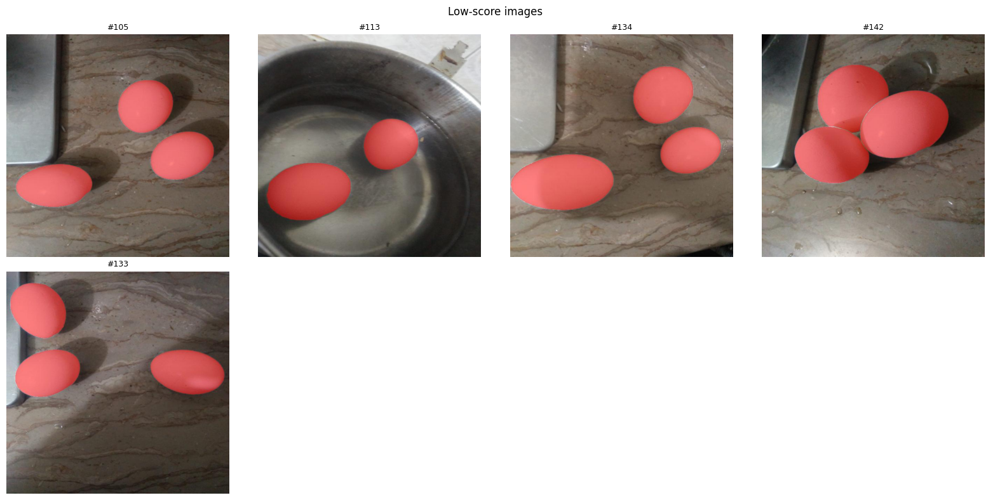

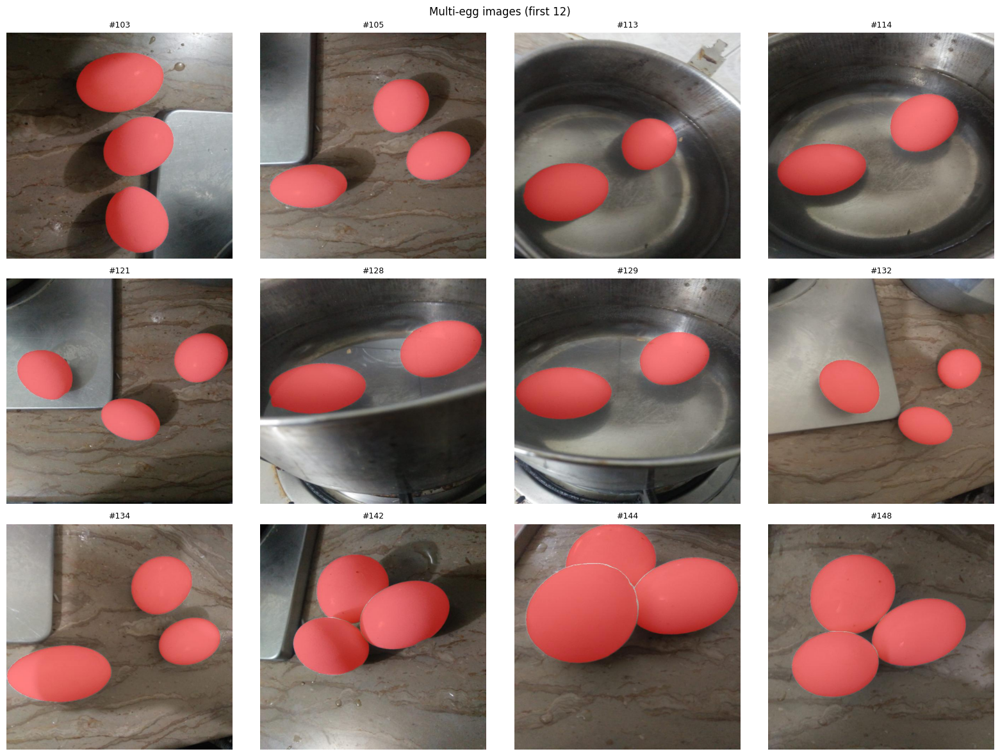

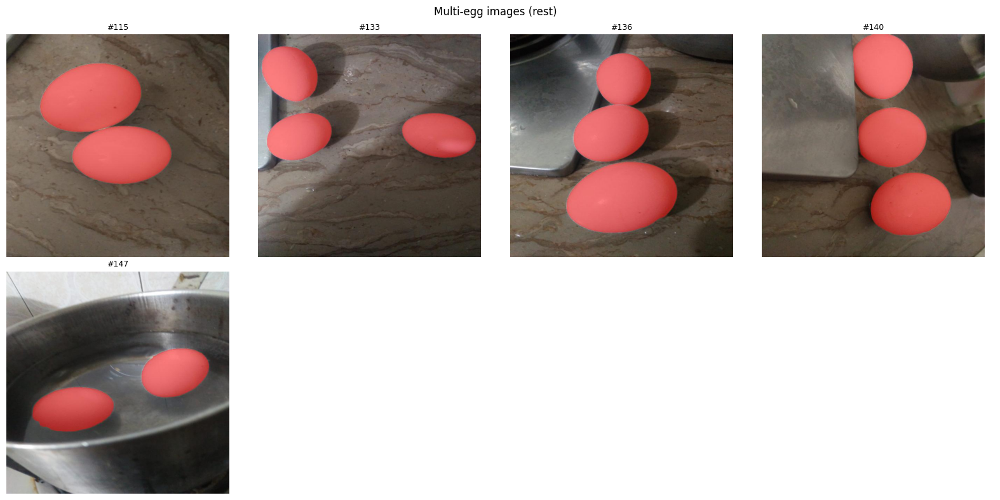

In [10]:
import matplotlib.pyplot as plt

def grid(names, cols=4, title=""):
    rows_n = int(np.ceil(len(names) / cols))
    fig, ax = plt.subplots(rows_n, cols, figsize=(4 * cols, 4 * rows_n))
    for a in np.array(ax).ravel(): a.axis("off")
    for a, n in zip(np.array(ax).ravel(), names):
        a.imshow(Image.open(f"{OUT}/overlays/{n}.jpg"))
        a.set_title(n.replace("not_damaged_", "#"), fontsize=9)
    plt.suptitle(title); plt.tight_layout(); plt.show()

low = ['not_damaged_105','not_damaged_113','not_damaged_134','not_damaged_142','not_damaged_133']
grid(low, title="Low-score images")

multi = df[df.n_eggs > 1]["image"].tolist()
grid(multi[:12], title="Multi-egg images (first 12)")
grid(multi[12:], title="Multi-egg images (rest)")

### 9. Systematic Inspection of Single-Egg Images
Grid inspection covering all single-egg instances across diverse backgrounds (hands, trays, boiling water, fabric).


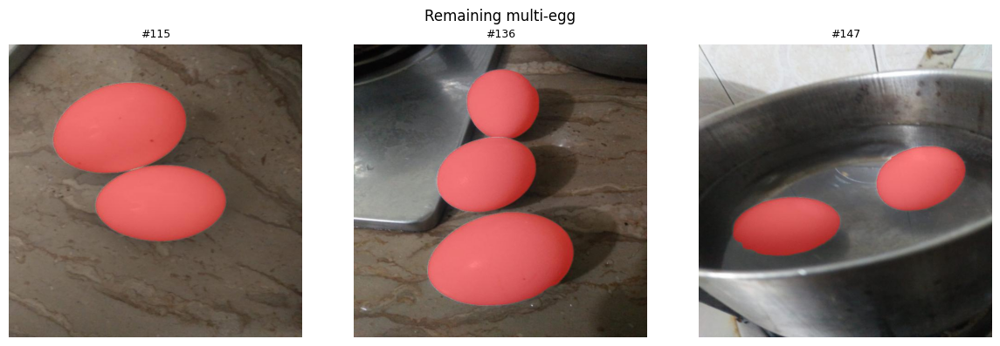

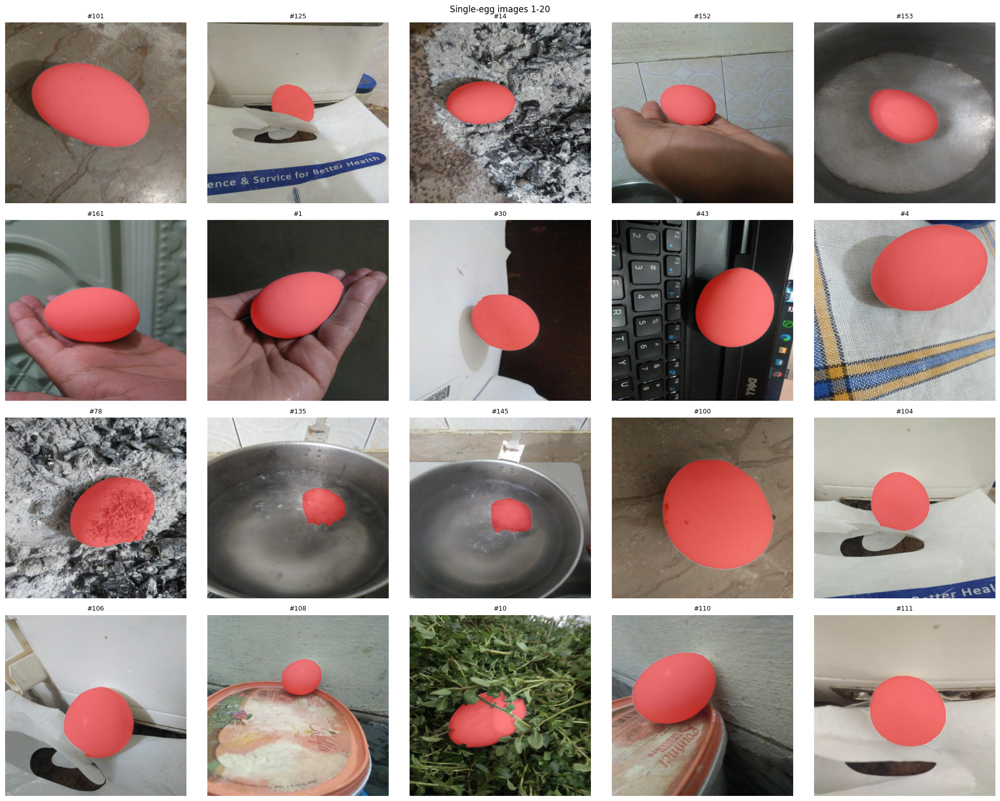

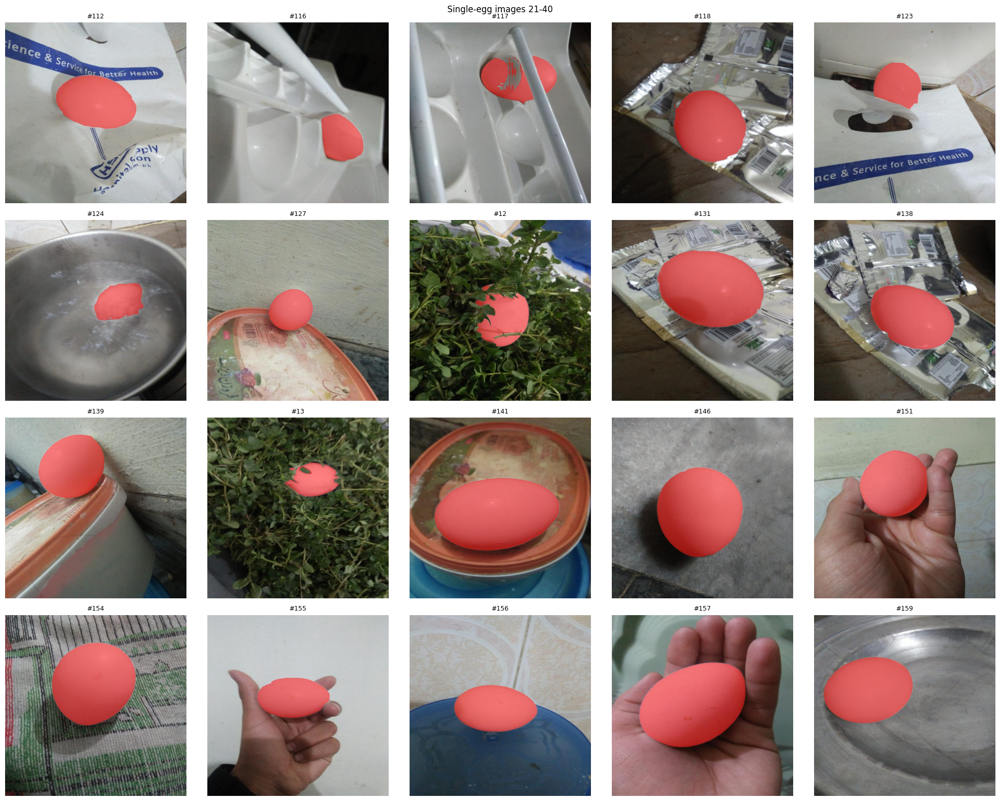

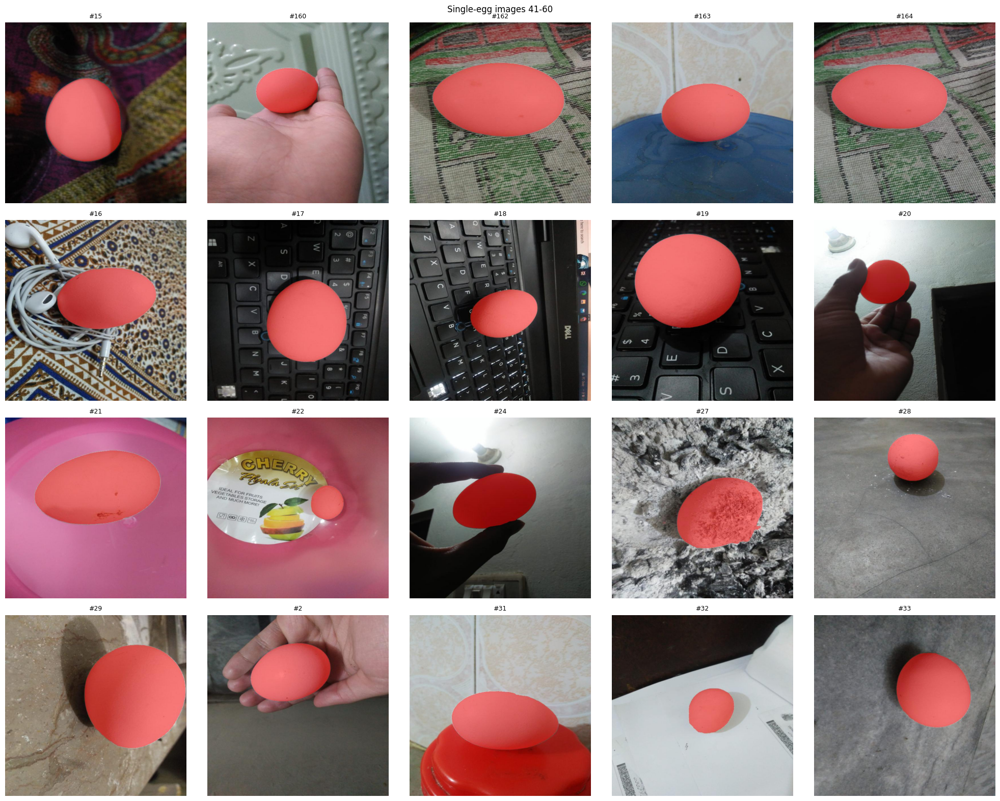

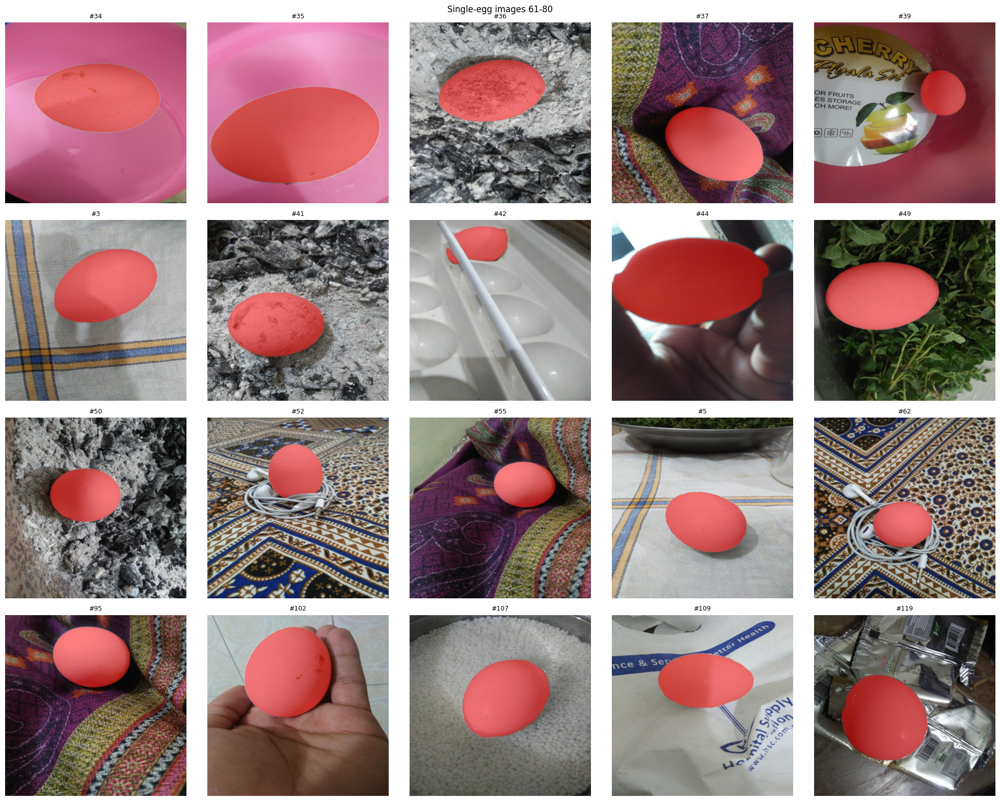

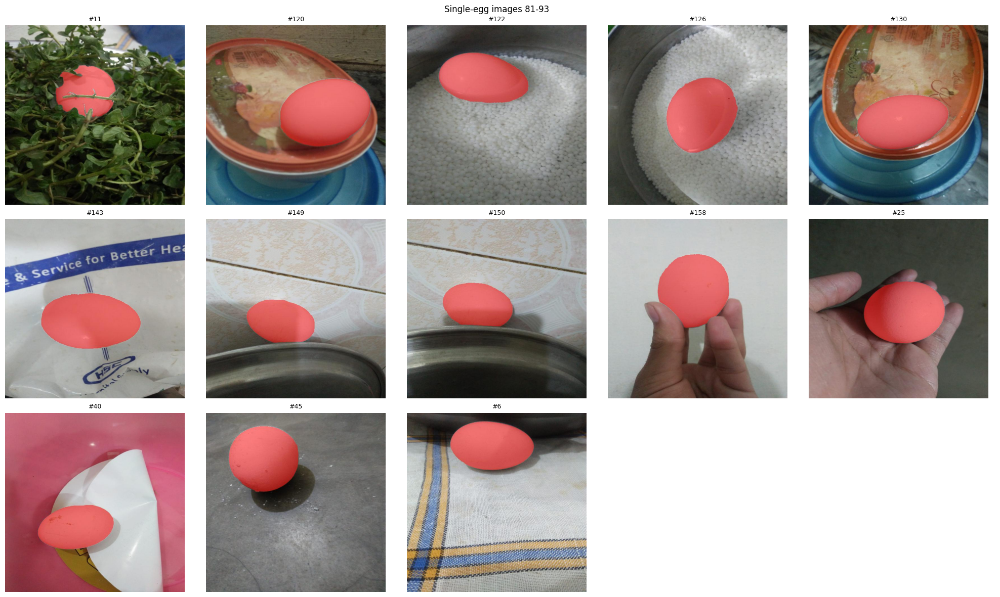

In [11]:
grid(['not_damaged_115','not_damaged_136','not_damaged_147'], cols=3, title="Remaining multi-egg")

singles = df[df.n_eggs == 1]["image"].tolist()
for i in range(0, len(singles), 20):
    grid(singles[i:i+20], cols=5, title=f"Single-egg images {i+1}-{min(i+20, len(singles))}")

### 10. Pseudo-Ground-Truth Stability: SAM-Base vs. SAM-Large
To ensure the pseudo-ground-truth masks are stable and trustworthy for Task 2 & Task 3 evaluation, compare predictions against the larger capacity `facebook/sam-vit-large` with multimask selection.


config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.25GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/482 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

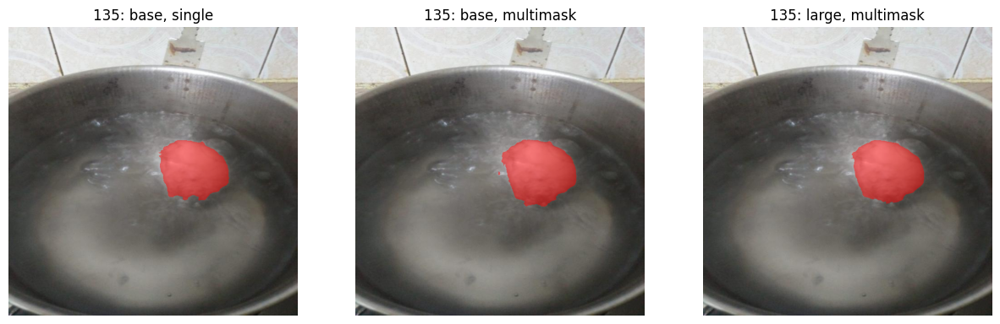

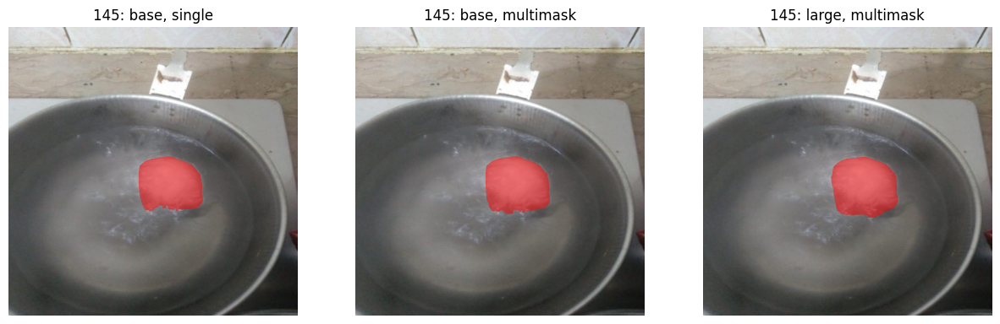

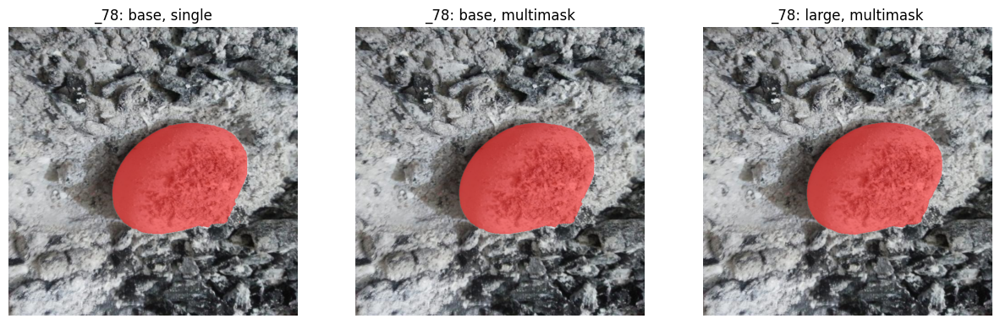

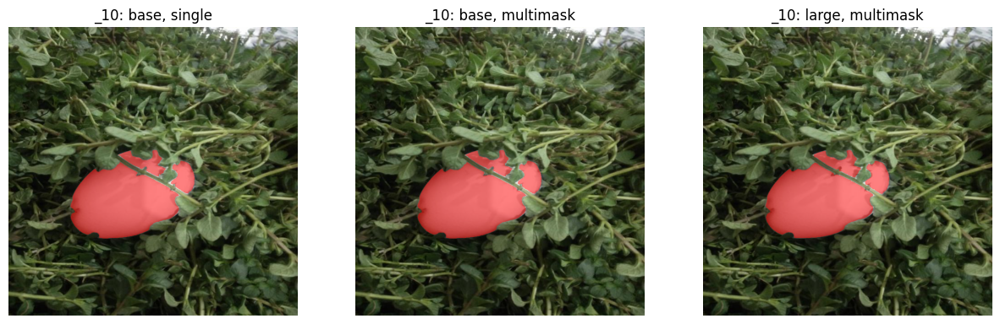

In [12]:
def segment_boxes_v2(img, boxes, model, proc):
    if len(boxes) == 0:
        return []
    inputs = proc(img, input_boxes=[boxes.tolist()], return_tensors="pt").to(device)
    with torch.no_grad():
        out = model(**inputs, multimask_output=True)
    masks = proc.image_processor.post_process_masks(
        out.pred_masks.cpu(), inputs["original_sizes"].cpu(),
        inputs["reshaped_input_sizes"].cpu(),
    )[0]                                  # (n_boxes, 3, H, W)
    ious = out.iou_scores.cpu()[0]        # (n_boxes, 3)
    result = []
    for i in range(masks.shape[0]):
        # pick the candidate with the highest predicted quality
        best = int(ious[i].argmax())
        result.append(masks[i, best].numpy().astype(bool))
    return result

# Load the larger SAM for comparison
sam_large = SamModel.from_pretrained("facebook/sam-vit-large").to(device).eval()
sam_large_proc = SamProcessor.from_pretrained("facebook/sam-vit-large")

def compare(name):
    p = [x for x in paths if f"{name}_jpg" in x][0]
    img = Image.open(p).convert("RGB")
    boxes, _ = detect_eggs(img)
    variants = {
        "base, single": segment_boxes(img, boxes),
        "base, multimask": segment_boxes_v2(img, boxes, sam, sam_proc),
        "large, multimask": segment_boxes_v2(img, boxes, sam_large, sam_large_proc),
    }
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    for a, (title, ms) in zip(ax, variants.items()):
        ov = np.array(img).copy()
        for m in ms:
            ov[m] = (0.5 * ov[m] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
        a.imshow(ov); a.set_title(f"{name[-3:]}: {title}"); a.axis("off")
    plt.show()

for n in ["not_damaged_135", "not_damaged_145", "not_damaged_78", "not_damaged_10"]:
    compare(n)

### 11. Side-by-Side Comparison on Complex Images
Evaluate potential boundary disagreements across 11 complex scenes (e.g. boiling water steam, partial occlusions, background clutter).


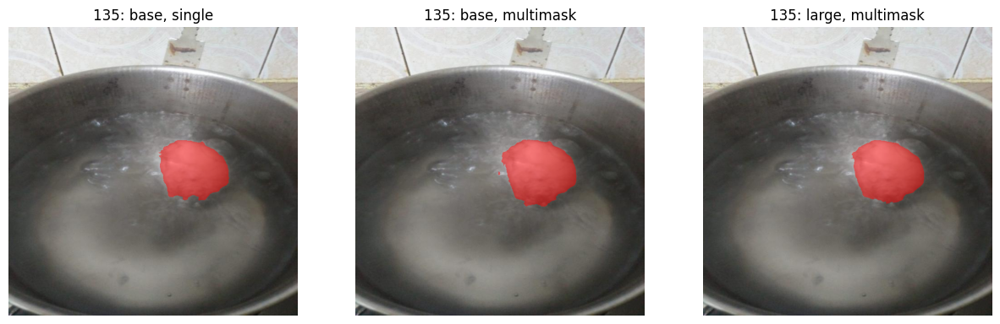

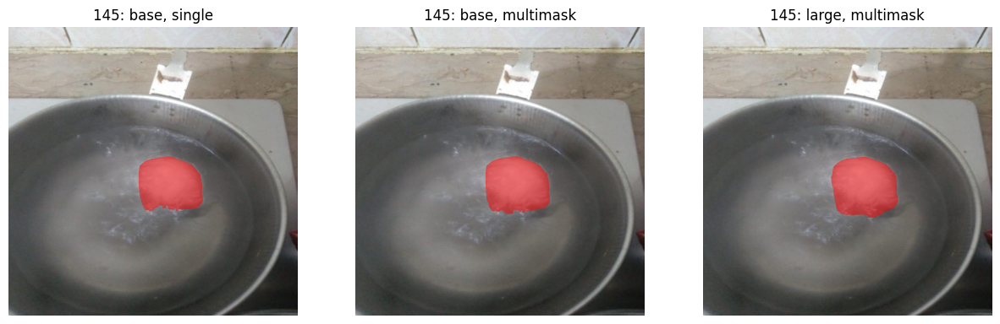

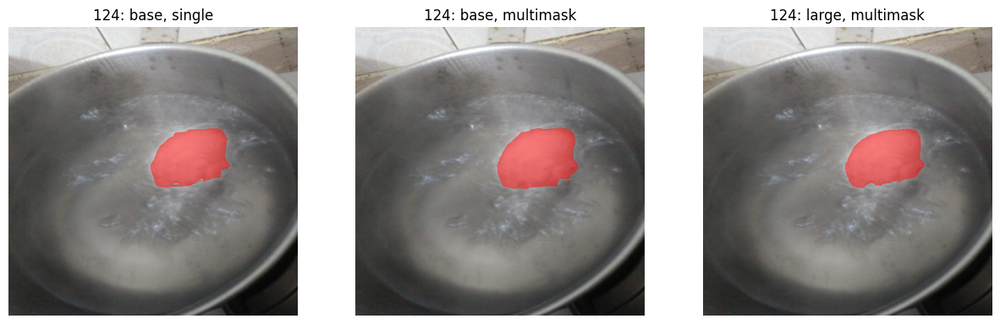

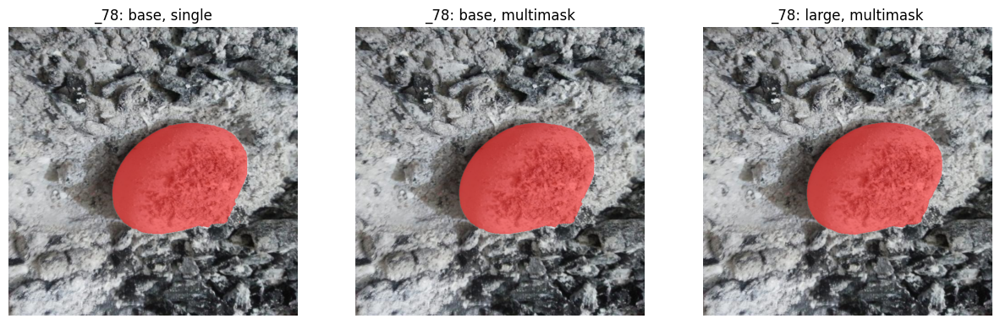

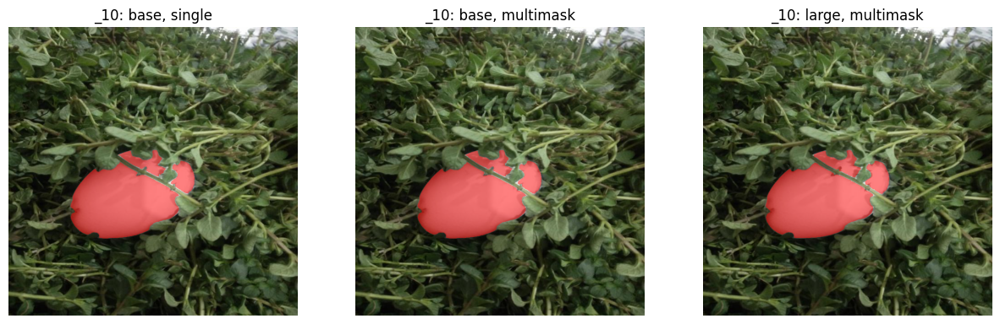

...

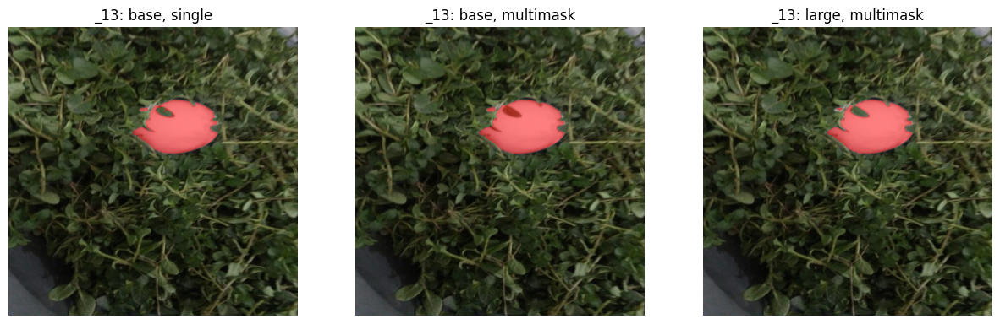

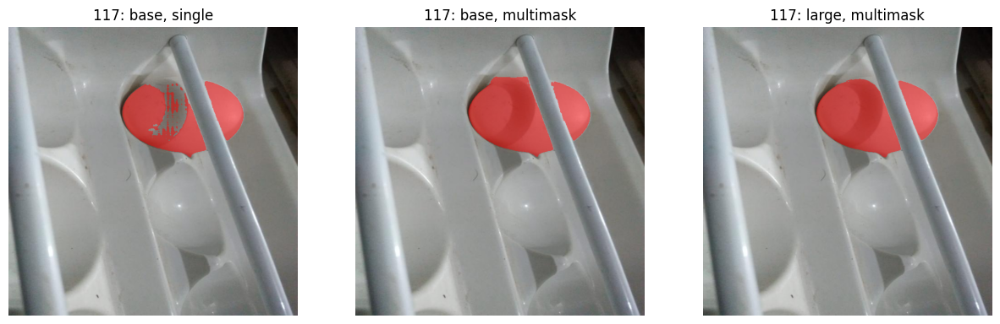

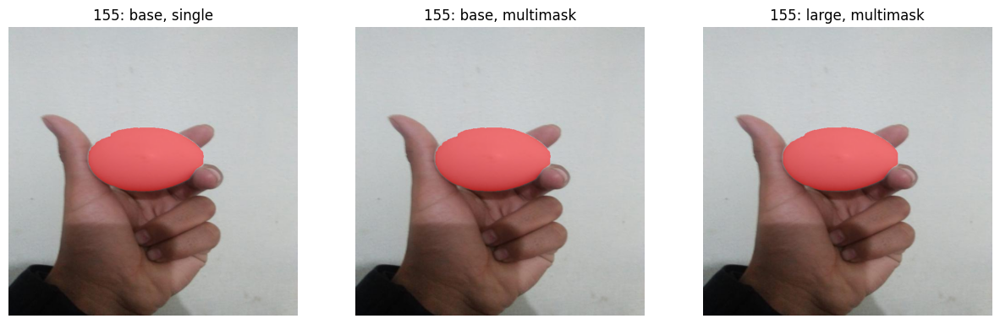

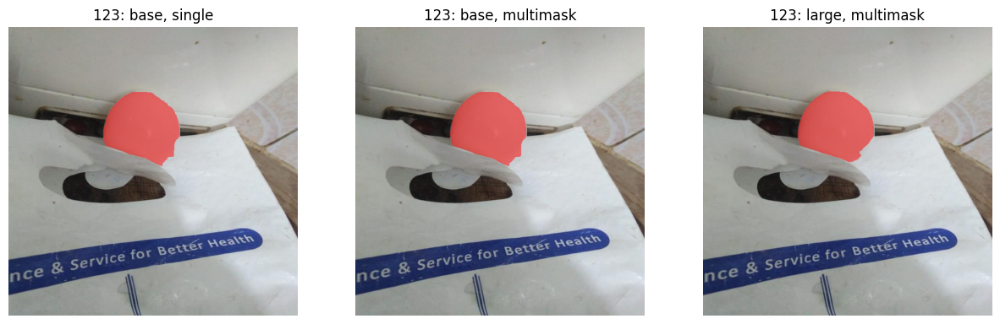

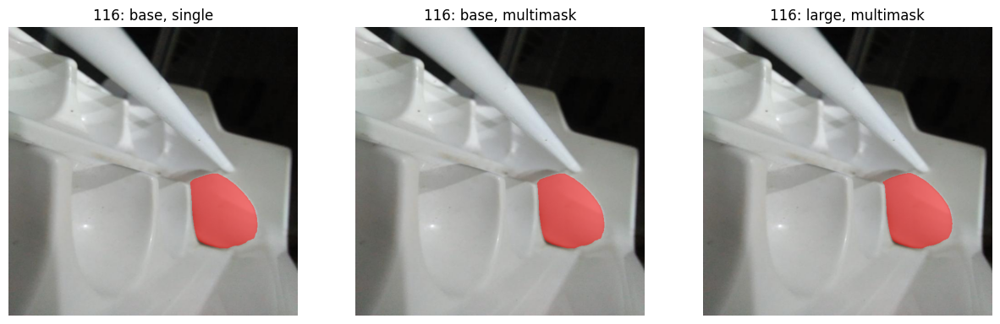

In [13]:
problem = ["135", "145", "124", "78", "10", "12", "13", "117", "155", "123", "116"]
for n in problem:
    compare(f"not_damaged_{n}")

### 12. Bounding Box Inspection
Examine exact coordinates and detector confidence for the edge cases.


In [14]:
def check_boxes(name):
    p = [x for x in paths if f"{name}_jpg" in x][0]
    img = Image.open(p).convert("RGB")
    boxes, scores = detect_eggs(img)
    print(name[-3:], [list(map(int, b)) for b in boxes], [round(float(s), 2) for s in scores])

for n in ["not_damaged_135", "not_damaged_124", "not_damaged_13"]:
    check_boxes(n)

135 [[321, 246, 493, 393]] [0.49]
124 [[306, 220, 496, 364]] [0.47]
_13 [[268, 157, 468, 282]] [0.93]


### 13. High-Resolution Inspection of Ambiguous Boundaries
Inspect zoomed crops of boiling water scenes (`135`, `145`, `124`) and leaf occlusion (`13`).


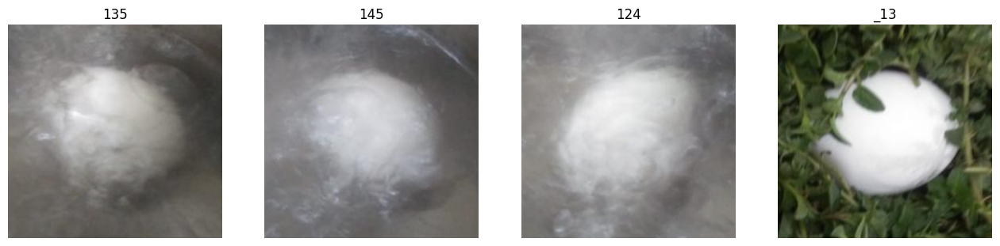

In [15]:
def crop(name, pad=40):
    p = [x for x in paths if f"{name}_jpg" in x][0]
    img = Image.open(p).convert("RGB")
    boxes, _ = detect_eggs(img)
    x0, y0, x1, y1 = boxes[0].astype(int)
    return img.crop((max(0, x0-pad), max(0, y0-pad), x1+pad, y1+pad)).resize((400, 400))

names = ["not_damaged_135", "not_damaged_145", "not_damaged_124", "not_damaged_13"]
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, n in zip(ax, names):
    a.imshow(crop(n)); a.set_title(n[-3:]); a.axis("off")
plt.show()

### 14. Quantitative Agreement Across Entire Dataset
Compute pairwise IoU between SAM-Base and SAM-Large across all 138 egg instances.


In [16]:
agree = []
for p in paths:
    name = os.path.basename(p).split("_jpg")[0]
    img = Image.open(p).convert("RGB")
    boxes, _ = detect_eggs(img, box_thr=0.3)
    mb = segment_boxes(img, boxes)
    ml = segment_boxes_v2(img, boxes, sam_large, sam_large_proc)
    for i, (a, b) in enumerate(zip(mb, ml)):
        agree.append((name, i + 1, (a & b).sum() / max((a | b).sum(), 1)))

ag = pd.DataFrame(agree, columns=["image", "egg", "iou_base_vs_large"])

### 15. Stability Analysis Results
**Output Interpretation:**
- **Median IoU = 0.995**; **Mean IoU = 0.990**.
- Out of 138 egg instances, **135 instances ($97.8\%$) have IoU $\ge 0.95$**.
- Only 3 instances fall below 0.95: `117` ($0.804$), `145` ($0.884$), `135` ($0.931$).
- **Conclusion:** Pseudo-ground-truth labels are exceptionally consistent and robust to model capacity, validating their use as reference masks for Task 2 & Task 3.


In [17]:
print("median:", round(ag.iou_base_vs_large.median(), 3))
print("mean:  ", round(ag.iou_base_vs_large.mean(), 3))
print("eggs below 0.95:", (ag.iou_base_vs_large < 0.95).sum(), "of", len(ag))
print(ag[ag.iou_base_vs_large < 0.95].sort_values("iou_base_vs_large").to_string(index=False))

median: 0.995
mean:   0.99
eggs below 0.95: 3 of 138
          image  egg  iou_base_vs_large
not_damaged_117    1           0.804140
not_damaged_145    1           0.883585
not_damaged_135    1           0.931455


### 16. Manual Override (Image 117) & Known Caveats
- **Image 117:** A metal rod crosses the egg on a low-contrast white tray. SAM-Base multimask resolved the full egg boundary correctly, so it was updated as an explicit override.
- Document known physical caveats (refraction in boiling water, ash texture, leaf occlusions) in `outputs/task1/caveats.json`.


In [18]:
def save_instance(name, masks, img):
    inst = np.zeros(img.size[::-1], dtype=np.uint8)
    for i, m in enumerate(masks, start=1):
        inst[m & (inst == 0)] = i
    Image.fromarray(inst).save(f"{OUT}/masks/{name}.png")
    ov = np.array(img).copy()
    for m in masks:
        ov[m] = (0.5 * ov[m] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    Image.fromarray(ov).save(f"{OUT}/overlays/{name}.jpg")

name = "not_damaged_117"
p = [x for x in paths if f"{name}_jpg" in x][0]
img = Image.open(p).convert("RGB")
boxes, _ = detect_eggs(img)
save_instance(name, segment_boxes_v2(img, boxes, sam, sam_proc), img)

# Ground-truth caveats for the report
import json
caveats = {
    "117": "override: base+multimask; rod crosses egg, white tray similar in tone",
    "135": "boiling water; blurred, ambiguous boundary (base/large IoU 0.93)",
    "145": "boiling water; blurred, ambiguous boundary (base/large IoU 0.88)",
    "124": "boiling water; blurred, ambiguous boundary",
    "78":  "ash on shell; slightly bumpy right edge",
    "10, 12, 13": "leaves occlude egg; masks exclude occluders (visible pixels only)",
}
json.dump(caveats, open(f"{OUT}/caveats.json", "w"), indent=2)

### 17. Final Verification of Remaining Samples


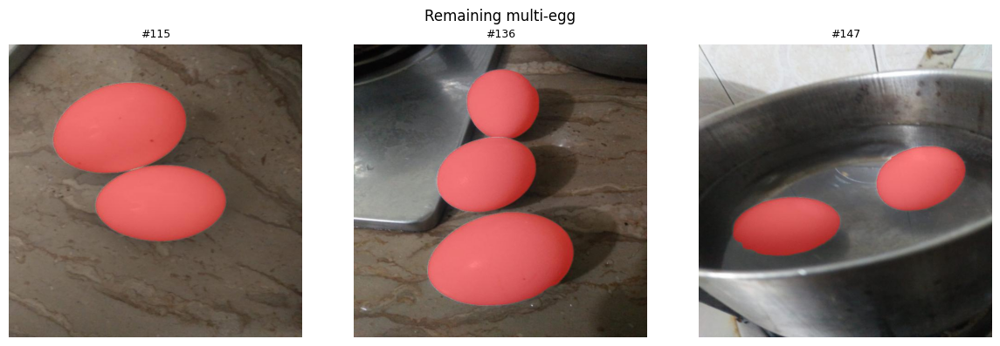

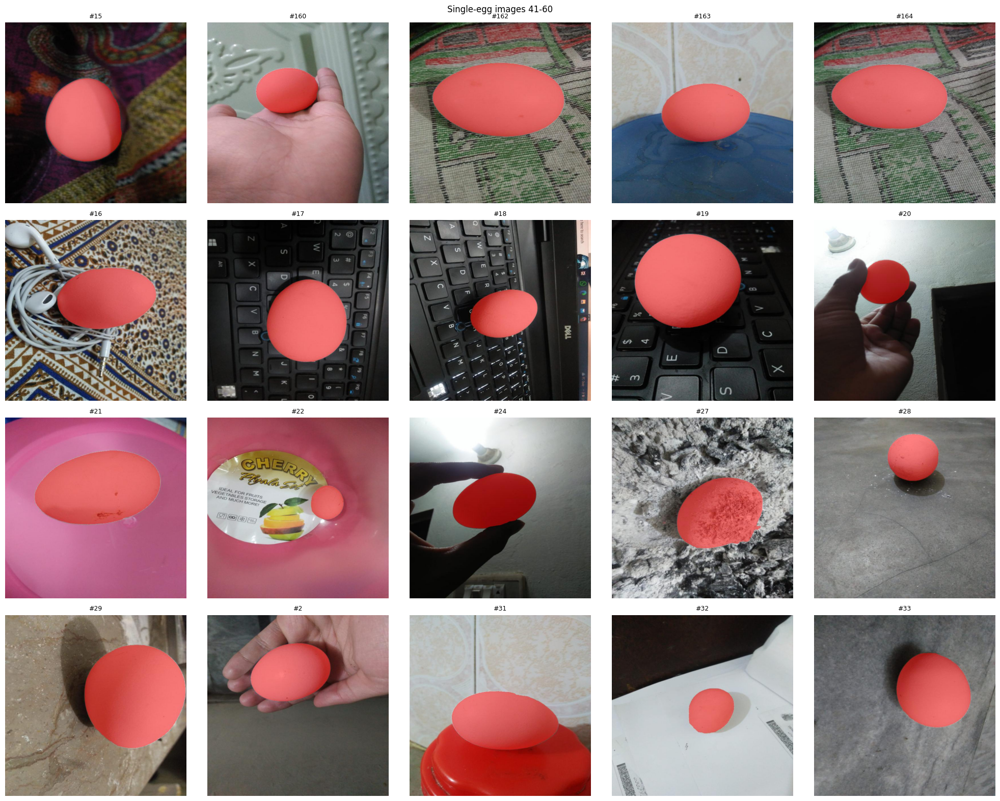

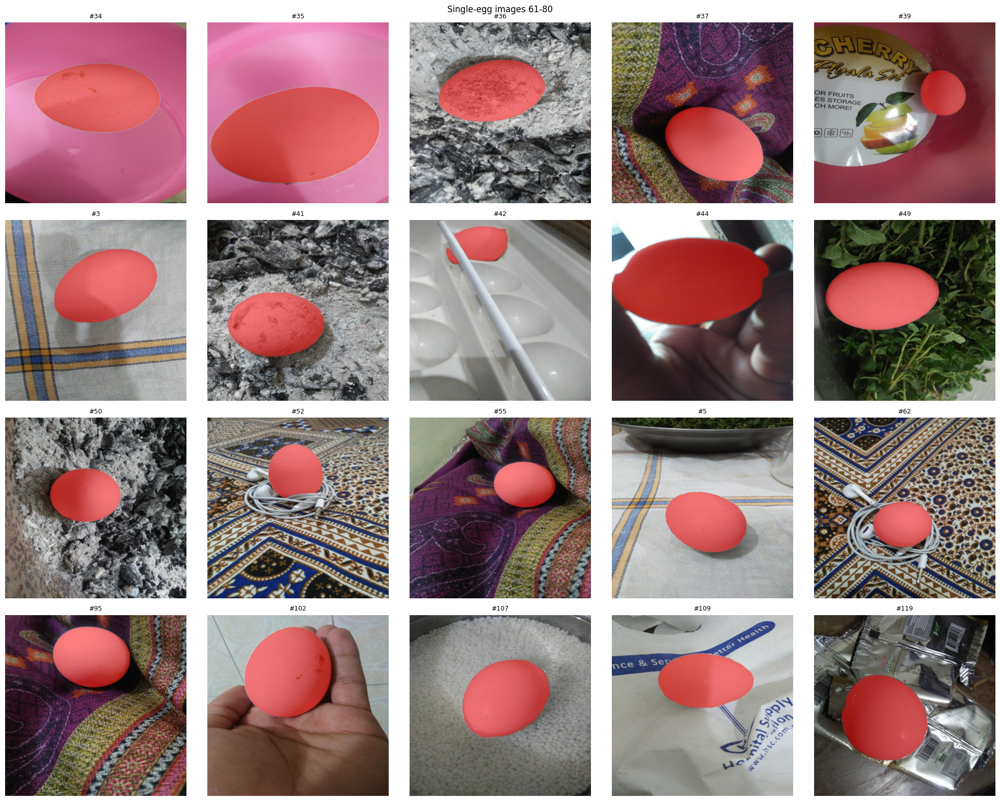

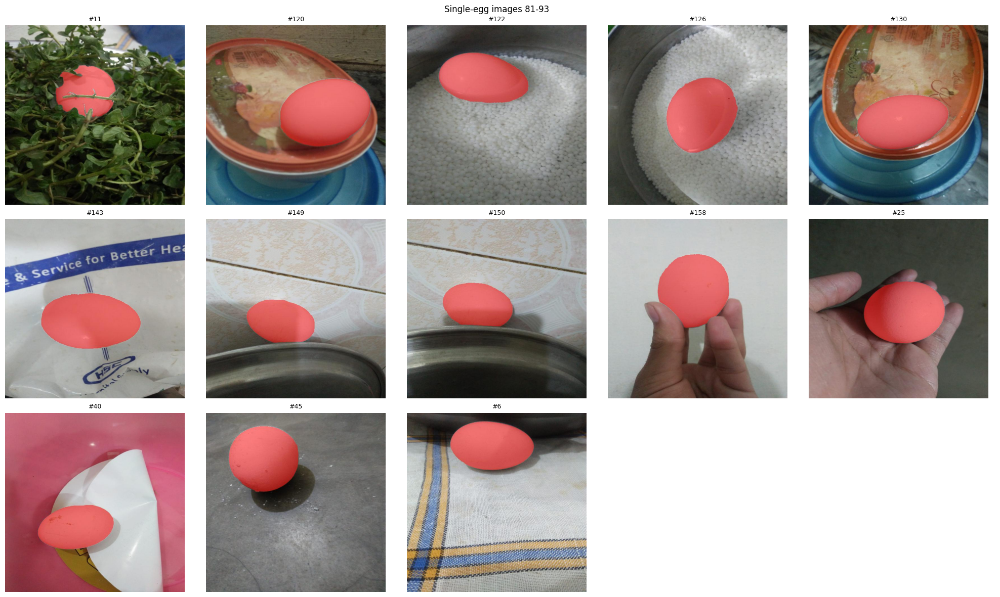

In [19]:
grid(['not_damaged_115','not_damaged_136','not_damaged_147'], cols=3, title="Remaining multi-egg")
singles = df[df.n_eggs == 1]["image"].tolist()
for i in range(40, len(singles), 20):
    grid(singles[i:i+20], cols=5, title=f"Single-egg images {i+1}-{min(i+20, len(singles))}")

### 18. Final Caveat Logging & Summary Dataset
Re-compile final dataset summary: **138 egg instances across 110 images** stored in `outputs/task1/summary_final.csv`.


In [20]:
caveats.update({
    "42":  "white tray; rod crosses egg; mask may be partial",
    "44":  "backlit hand; dark egg edge, rough left boundary",
    "11":  "leaves/stem occlude egg; visible pixels only",
})
json.dump(caveats, open(f"{OUT}/caveats.json", "w"), indent=2)

# regenerate the summary so it reflects the 117 override
rows = []
for p in paths:
    name = os.path.basename(p).split("_jpg")[0]
    inst = np.array(Image.open(f"{OUT}/masks/{name}.png"))
    ids = [i for i in np.unique(inst) if i != 0]
    rows.append({"image": name, "n_eggs": len(ids),
                 "areas": [int((inst == i).sum()) for i in ids]})
pd.DataFrame(rows).to_csv(f"{OUT}/summary_final.csv", index=False)
print(sum(r["n_eggs"] for r in rows), "egg instances in", len(rows), "images")

138 egg instances in 110 images


### 19. Export Outputs
Package generated masks, overlays, and metadata into a zip archive for Task 2 and Task 3.


In [21]:
!cd /content/outputs && zip -rq task1_outputs.zip task1
from google.colab import files
files.download("/content/outputs/task1_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>